In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer, recall_score, precision_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score, recall_score
from sklearn.base import clone


sns.set_theme(style="whitegrid")

RANDOM_STATE = 0

In [2]:
# Load dataset & check columns
df = pd.read_csv('../data/clean/cleaned_dataframe.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            61069 non-null  int64  
 1   class                 61069 non-null  str    
 2   cap-color             61069 non-null  str    
 3   cap-shape             61069 non-null  str    
 4   does-bruise-or-bleed  61069 non-null  str    
 5   gill-color            61069 non-null  str    
 6   has-ring              61069 non-null  str    
 7   season                61069 non-null  str    
 8   habitat               61069 non-null  str    
 9   cap-diameter          61069 non-null  float64
 10  stem-height           61069 non-null  float64
 11  stem-width            61069 non-null  float64
dtypes: float64(3), int64(1), str(8)
memory usage: 5.6 MB


In [3]:
# Drop Unnamed column

df = df.drop(columns="Unnamed: 0")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  str    
 1   cap-color             61069 non-null  str    
 2   cap-shape             61069 non-null  str    
 3   does-bruise-or-bleed  61069 non-null  str    
 4   gill-color            61069 non-null  str    
 5   has-ring              61069 non-null  str    
 6   season                61069 non-null  str    
 7   habitat               61069 non-null  str    
 8   cap-diameter          61069 non-null  float64
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
dtypes: float64(3), str(8)
memory usage: 5.1 MB


In [4]:
# Count and remove duplicate rows

print(f"Duplicate rows removed: {df.duplicated().sum()}")
df = df.drop_duplicates().reset_index(drop=True)

Duplicate rows removed: 166


In [5]:
# We split the data into train and test

X_mush = df.drop(columns="class")
y_mush = df["class"]

X_train_mush, X_test_mush, y_train_mush, y_test_mush = train_test_split(
    X_mush,
    y_mush,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_mush,
)

print("Training observations:", len(X_train_mush))
print("Test observations:", len(X_test_mush))
print("Training features:", list(X_train_mush.columns))

Training observations: 48722
Test observations: 12181
Training features: ['cap-color', 'cap-shape', 'does-bruise-or-bleed', 'gill-color', 'has-ring', 'season', 'habitat', 'cap-diameter', 'stem-height', 'stem-width']


In [6]:
# Split features by type

numeric_features = ["cap-diameter", 'stem-height', 'stem-width']
nominal_features = [    "cap-color", "cap-shape","does-bruise-or-bleed", "gill-color", "has-ring", "season", "habitat"]


In [7]:
# Define the enconder for Nominal features

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train_mush[nominal_features])

encoded_train = pd.DataFrame(
    encoder.transform(X_train_mush[nominal_features]),
    columns=encoder.get_feature_names_out(),
    index=X_train_mush.index,
)
display(encoded_train.head())


,cap-color_b,cap-color_e,cap-color_g,cap-color_k,cap-color_l,cap-color_n,cap-color_o,cap-color_p,cap-color_r,cap-color_u,...,season_u,season_w,habitat_d,habitat_g,habitat_h,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
2776,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24046,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
44651,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1754,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
50027,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
# Creating a pipeline for Nominal features

nominal_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore')),
])

print(nominal_pipeline)

Pipeline(steps=[('encoder', OneHotEncoder(handle_unknown='ignore'))])


In [9]:
# Scale Numerical features
scaler = StandardScaler()

scaled_train = pd.DataFrame(
    scaler.fit_transform(X_train_mush[numeric_features]),
    columns=numeric_features,
    index=X_train_mush.index,
)

scaled_test = pd.DataFrame(
    scaler.transform(X_test_mush[numeric_features]),
    columns=numeric_features,
    index=X_test_mush.index,
)

In [10]:
# Creating a pipeline for Numerical features

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', scaler),
])

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


In [11]:
# Combine nominal and numerical features

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("nominal", nominal_pipeline, nominal_features),
])

model = Pipeline([
    ("preprocessing", preprocessor),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

model.fit(X_train_mush, y_train_mush)
y_pred = model.predict(X_test_mush)

In [12]:
y_pred

array(['p', 'p', 'e', ..., 'p', 'p', 'e'], shape=(12181,), dtype=object)

              precision    recall  f1-score   support

      Edible       0.99      0.99      0.99      5436
   Poisonous       0.99      0.99      0.99      6745

    accuracy                           0.99     12181
   macro avg       0.99      0.99      0.99     12181
weighted avg       0.99      0.99      0.99     12181



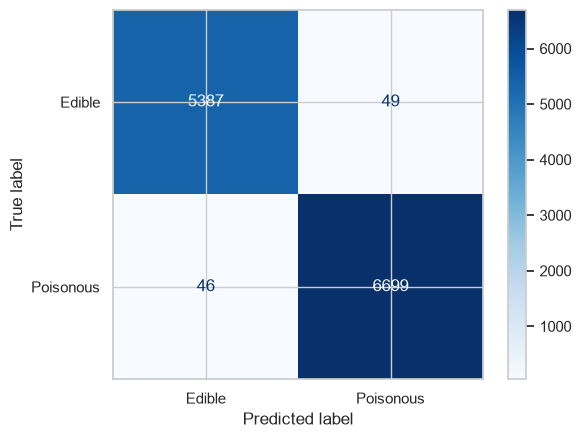

In [13]:
# Evaluate predictions

print(classification_report(
    y_test_mush,
    y_pred,
    labels=["e", "p"],
    target_names=["Edible", "Poisonous"],
))

ConfusionMatrixDisplay.from_predictions(
    y_test_mush,
    y_pred,
    labels=["e", "p"],
    display_labels=["Edible", "Poisonous"],
    cmap="Blues",
)
plt.show()

In [14]:
# Compare Test and Training accuracy to check if there is overfitting or underfitting

train_accuracy = model.score(X_train_mush, y_train_mush)
test_accuracy = model.score(X_test_mush, y_test_mush)

print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Test accuracy:     {test_accuracy:.2%}")
print(f"Accuracy gap:     {(train_accuracy - test_accuracy) * 100:.2f} percentage points")

Training accuracy: 99.36%
Test accuracy:     99.22%
Accuracy gap:     0.14 percentage points


In [15]:
# Check how many mushrooms have been wrongly classified

missed_poisonous = ((y_test_mush == "p") & (y_pred == "e")).sum()
print(f"Poisonous mushrooms predicted as edible: {missed_poisonous}")

Poisonous mushrooms predicted as edible: 46


In [16]:
# Train KNN and generate predictions without scaling
model_unscaled = clone(model)

model_unscaled.set_params(preprocessing__numeric__scaler="passthrough")

model_unscaled.fit(X_train_mush, y_train_mush)

y_pred_unscaled = model_unscaled.predict(X_test_mush)

In [17]:
# Compare both models' overall performance (with and without scaling)
results = []

for scaling, predictions in [
    ("With scaling", y_pred),
    ("Without scaling", y_pred_unscaled),
]:

    results.append({
        "Model": scaling,
        "Accuracy": accuracy_score(y_test_mush, predictions),
        "Macro F1": f1_score(y_test_mush, predictions, average="macro"),
        "Poisonous recall": recall_score(
            y_test_mush, predictions, pos_label="p"
        ),
        "Poisonous predicted as edible": (
            (y_test_mush == "p") & (predictions == "e")
        ).sum(),
    })


comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(4))

,Accuracy,Macro F1,Poisonous recall,Poisonous predicted as edible
Model,,,,
With scaling,0.9922,0.9921,0.9932,46
Without scaling,0.9894,0.9893,0.9907,63


In [19]:
# Tune the number of neighbors with four-fold cross-validation, including our baseline (k=5)

# tune the number of neighbors (k is the only setting we change)
param_grid_knn = {
    "knn__n_neighbors": [3, 5, 9, 15],
    "knn__weights": ["uniform", "distance"],
}

# metrics we track for every k
scoring = {
    "accuracy": "accuracy",
    "balanced_acc": "balanced_accuracy",
    "recall_poison": make_scorer(recall_score, pos_label="p", zero_division=0), # poisnous caught
    "precision_edible": make_scorer(precision_score, pos_label="e", zero_division=0), 
}

# 5-fold cv runs inside the grid search: each k is trained and scored 5 times
# (4 values x 5 folds = 20 fits), the mean of the 5 scores decides the best k,
# which is then refit on the full training set. test set is not used here.
# 24 combinations × 5 folds = 120 CV fits, plus one final refit

grid = GridSearchCV(
    model,
    param_grid_knn,
    scoring=scoring,
    refit="balanced_acc",
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE,
    ),
    return_train_score=False,
    n_jobs= 1,  
)


grid.fit(X_train_mush, y_train_mush)
best_knn = grid.best_estimator_
print("Best params:", grid.best_params_)


C:\Users\Preeti\desktop\ironhack\week_7\day_1\machine_learning_mini-project\.venv\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan]
  warnings.warn(


Best params: {'knn__n_neighbors': 3, 'knn__weights': 'uniform'}


In [33]:
print(model.get_params()["knn__p"])

2


In [26]:
start = time.perf_counter()
grid.fit(X_train_mush, y_train_mush)
print(f"Runtime: {time.perf_counter() - start:.2f} seconds")

Runtime: 2038.24 seconds


In [20]:
# cv numbers of the best k (mean +- std over the 5 folds)
i = grid.best_index_
r = grid.cv_results_
cv_recall   = r["mean_test_recall_poison"][i]
cv_bal_acc  = r["mean_test_balanced_acc"][i]
prec_edible = r["mean_test_precision_edible"][i]

# no train scores were saved for knn, so train accuracy is checked once on the best model
gap = best_knn.score(X_train_mush, y_train_mush) - r["mean_test_accuracy"][i]

print(f"CV recall (poisonous): {cv_recall:.4f} ± {r['std_test_recall_poison'][i]:.4f}")
print(f"CV balanced accuracy:  {cv_bal_acc:.4f} ± {r['std_test_balanced_acc'][i]:.4f}")
print(f"CV precision (edible): {prec_edible:.4f} ± {r['std_test_precision_edible'][i]:.4f}")
print(f"Train - CV gap:        {gap:.4f}")

#comparison_line("KNN", cv_recall, cv_bal_acc, prec_edible, gap, total_train_time)

CV recall (poisonous): nan ± nan
CV balanced accuracy:  nan ± nan
CV precision (edible): nan ± nan
Train - CV gap:        nan


              precision    recall  f1-score   support

      Edible       0.99      0.99      0.99      5436
   Poisonous       0.99      0.99      0.99      6745

    accuracy                           0.99     12181
   macro avg       0.99      0.99      0.99     12181
weighted avg       0.99      0.99      0.99     12181



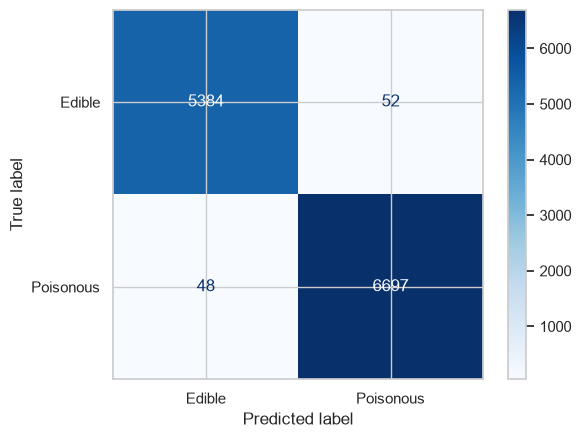

Training accuracy: 100.00%
Test accuracy:     99.18%


In [31]:
# test set is only used here, once, after the tuning is finished
y_pred_tree = best_knn.predict(X_test_mush)
print(classification_report(y_test_mush, y_pred_tree, labels=["e", "p"],
                            target_names=["Edible", "Poisonous"]))

ConfusionMatrixDisplay.from_predictions(
    y_test_mush, y_pred_tree, labels=["e", "p"],
    display_labels=["Edible", "Poisonous"], cmap="Blues")
plt.show()

print(f"Training accuracy: {best_knn.score(X_train_mush, y_train_mush):.2%}")
print(f"Test accuracy:     {best_knn.score(X_test_mush, y_test_mush):.2%}")

In [20]:
# Show the mean validation accuracy for each value of k
cv_results = pd.DataFrame(grid_search.cv_results_)

display(
    cv_results[
        ["param_knn__n_neighbors", "mean_test_score", "rank_test_score"]
    ]
    .rename(columns={
        "param_knn__n_neighbors": "Number of neighbors",
        "mean_test_score": "Mean CV accuracy",
        "rank_test_score": "Rank",
    })
    .sort_values("Rank")
    .round(4)
)

,Number of neighbors,Mean CV accuracy,Rank
0,3,0.9907,1
1,5,0.9893,2
2,7,0.9873,3
3,11,0.9829,4


In [21]:
# Evaluate the selected KNN model on the test set
best_knn = grid_search.best_estimator_
y_pred_tuned = best_knn.predict(X_test_mush)

print(classification_report(
    y_test_mush,
    y_pred_tuned,
    labels=["e", "p"],
    target_names=["Edible", "Poisonous"],
    digits=4,
))

missed_poisonous_tuned = ((y_test_mush == "p") & (y_pred_tuned == "e")).sum()
print(f"Poisonous mushrooms predicted as edible: {missed_poisonous_tuned}")

              precision    recall  f1-score   support

      Edible     0.9913    0.9908    0.9911      5436
   Poisonous     0.9926    0.9930    0.9928      6745

    accuracy                         0.9920     12181
   macro avg     0.9920    0.9919    0.9919     12181
weighted avg     0.9920    0.9920    0.9920     12181

Poisonous mushrooms predicted as edible: 47


## Conclusions

We trained a K-Nearest Neighbors classifier (`k=5`) to predict whether a mushroom is edible or poisonous using ten features from the secondary dataset. We removed exact duplicate rows before creating a stratified 80/20 train/test split. The preprocessing pipeline learned its settings from the training data.

### Model performance

The scaled KNN model achieved **99.36% training accuracy** and **99.22% test accuracy**, a gap of **0.14 percentage points**. The two scores were high and close, showing little evidence of substantial overfitting or underfitting on this split.

On the test set, the model achieved a **macro F1 score of 0.9921** and correctly flagged **99.32% of poisonous mushrooms**. It still classified **46 poisonous mushrooms as edible**. This error count matters for the proposed app because it shows how often the model missed a poisonous mushroom despite high overall accuracy.

### Effect of scaling

We compared KNN with and without scaling the three numerical features, using the same data split, one-hot encoding, and number of neighbors. Scaling changes how much each measurement contributes to the distances KNN uses to find similar mushrooms.

| Test metric | Without scaling | With scaling |
|---|---:|---:|
| Accuracy | 98.94% | 99.22% |
| Macro F1 | 0.9893 | 0.9921 |
| Poisonous recall | 99.07% | 99.32% |
| Poisonous mushrooms predicted as edible | 63 | 46 |

Scaling improved all four metrics on this split. Test accuracy rose by **0.28 percentage points**, and the model classified **17 fewer poisonous mushrooms as edible**, a reduction of about **27%**. We selected the scaled pipeline as our KNN configuration for the team's model comparison.

### Hyperparameter tuning

We used four-fold cross-validation on the training set to compare KNN with `k=3`, `5`, `7`, and `11`. Grid search selected `k=3`, which had the highest mean validation accuracy at **99.07%**, compared with **98.93%** for our `k=5` baseline.

| Test metric | Baseline (`k=5`) | Selected model (`k=3`) |
|---|---:|---:|
| Accuracy | 99.22% | 99.20% |
| Macro F1 | 0.9921 | 0.9919 |
| Poisonous recall | 99.32% | 99.30% |
| Poisonous mushrooms predicted as edible | 46 | 47 |

The validation results favored `k=3` by a small margin. On the test split, both configurations performed similarly, with `k=5` scoring slightly higher and classifying one fewer poisonous mushroom as edible.